In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

def OS_fit(xdata,ydata):
    return curve_fit(OS_model, xdata, ydata,
                       p0=[ydata[0], ydata.max(), ydata[-1], 
                           xdata[np.argmax(ydata)], 10 , (xdata[-1]-xdata[np.argmax(ydata)])/2],
                       bounds = ([ydata[0]-0.5, ydata.max()-0.5, ydata[-1]-0.5, 
                                  0, 0, 0],
                                 [ydata[0]+0.5, ydata.max()+0.5, ydata[-1]+0.5, 
                                  len(xdata), 100, len(xdata)]) )

In [2]:
folder = '../../Data/PROVIDE 2025/fair_temperatures/'
scenarios = os.listdir(folder)

baseline = 'ssp534-over'
df = pd.read_csv(folder+'scen_%s.csv'%baseline)
df=df.set_index('year')
years = df.index.values
temps=df.to_numpy()

In [25]:
scenarios

['scen_ModAct nz 2120 decline -16500.csv',
 'scen_LD_NZGHG.csv',
 'scen_ssp534-over.csv',
 'scen_Neg.csv',
 'scen_CurPol.csv',
 'scen_Ren_NZCO2.csv',
 'scen_GS.csv',
 'scen_Neg_NZGHG.csv',
 'scen_SP_NZGHG.csv',
 'scen_LD.csv',
 'scen_GS_NZGHG.csv',
 'scen_SP.csv',
 'scen_Neg nz 2100 decline -17000.csv',
 'scen_Ref_1p5.csv',
 'scen_CurPol nz 2120 decline -23800.csv',
 'scen_ModAct nz 2120 decline -23000.csv',
 'scen_Ren.csv',
 'scen_ModAct.csv',
 'scen_ssp119.csv']

In [4]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,2227,2228,2229,2230,2231,2232,2233,2234,2235,2236
year,,,,,,,,,,,,,,,,,,,,,
1850,0.0125,-0.0153,0.0035,0.0768,0.0415,0.0397,0.0040,0.0204,0.0051,0.0292,...,0.0067,0.0096,-0.0040,0.0318,0.0014,-0.0136,0.0237,-0.0070,-0.0185,-0.0287
1851,0.0247,-0.0062,0.0118,0.0796,0.0496,0.0475,0.0123,0.0279,0.0141,0.0409,...,0.0163,0.0165,0.0045,0.0383,0.0123,-0.0004,0.0337,0.0029,-0.0049,-0.0118
1852,0.0343,0.0004,0.0164,0.0811,0.0555,0.0532,0.0172,0.0339,0.0204,0.0498,...,0.0235,0.0214,0.0109,0.0425,0.0208,0.0095,0.0411,0.0101,0.0056,0.0020
1853,0.0316,-0.0029,0.0062,0.0718,0.0490,0.0464,0.0085,0.0314,0.0130,0.0449,...,0.0201,0.0152,0.0083,0.0343,0.0180,0.0049,0.0361,0.0069,0.0041,0.0030
1854,0.0178,-0.0146,-0.0133,0.0531,0.0311,0.0289,-0.0097,0.0208,-0.0053,0.0274,...,0.0072,0.0004,-0.0026,0.0157,0.0055,-0.0121,0.0196,-0.0057,-0.0085,-0.0079


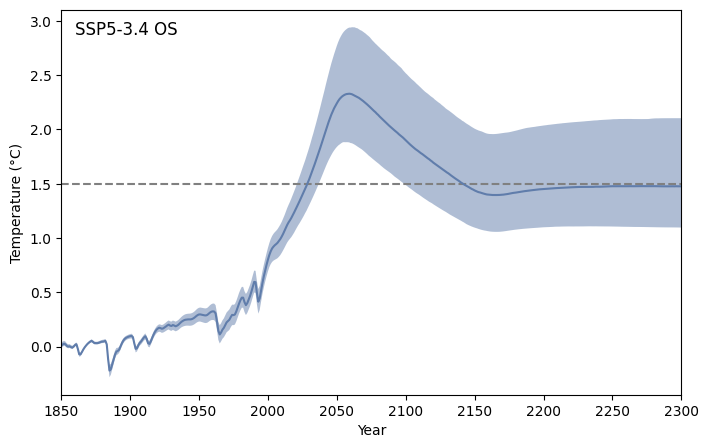

In [30]:
fig,ax=plt.subplots(figsize=(8,5))
ax.plot([1850,2300],[1.5]*2,c='gray',ls='--')
ax.fill_between(years,np.quantile(temps,0.1,axis=1),np.quantile(temps,0.9,axis=1),
                alpha=0.5,color='#607dab',edgecolor='none')
ax.plot(years,np.median(temps,axis=1),color='#607dab')

ax.set_xlabel('Year')
ax.set_ylabel('Temperature (°C)')
ax.set_xlim(1850,2300)
ax.text(1860,3,'SSP5-3.4 OS',ha='left',va='top',fontsize=12)
# ax.scatter([2015],[np.median(temps,axis=1)[2015-1850]])
fig.savefig('../../Figures/Overshoots/Conference/ssp534.png',bbox_inches='tight')

In [3]:
baseline = 'ssp534-over'
folder_ensemble = '../../Data/PROVIDE 2025/fair_temperatures/'
df_ensemble = pd.read_csv(folder_ensemble+'scen_%s.csv'%baseline)
df_ensemble=df_ensemble.set_index('year')
years_ensemble = df_ensemble.index.values
temps_ensemble=df_ensemble.to_numpy()

t_ref = 2015
xdata=years_ensemble[t_ref-1850:]-t_ref
popts = np.array([OS_fit(xdata,temps_ensemble[t_ref-1850:,r])[0] for r in range(temps_ensemble.shape[1])])
popt_of_m,_ = OS_fit(xdata,np.median(temps_ensemble[t_ref-1850:,:],axis=1))

In [4]:
popts.shape

(2237, 6)

<>:17: SyntaxWarning: invalid escape sequence '\D'
<>:21: SyntaxWarning: invalid escape sequence '\D'
<>:25: SyntaxWarning: invalid escape sequence '\D'
<>:17: SyntaxWarning: invalid escape sequence '\D'
<>:21: SyntaxWarning: invalid escape sequence '\D'
<>:25: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_708646/2480913241.py:17: SyntaxWarning: invalid escape sequence '\D'
  ax.text(popt_of_m[3]/2,popt_of_m[0],'$\Delta t_u$',va='bottom',ha='center',fontsize=12)
/tmp/ipykernel_708646/2480913241.py:21: SyntaxWarning: invalid escape sequence '\D'
  '$\Delta t_p$',va='top',ha='center',fontsize=12)
/tmp/ipykernel_708646/2480913241.py:25: SyntaxWarning: invalid escape sequence '\D'
  '$\Delta t_d$',va='top',ha='center',fontsize=12)


Text(87.6760746361413, 1.4350968152787789, '$\\Delta t_d$')

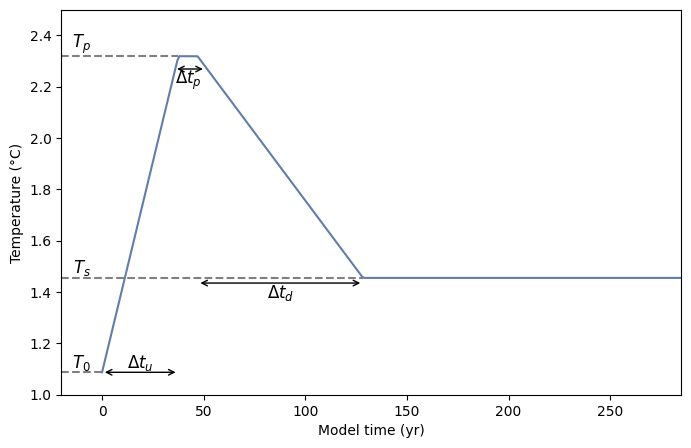

In [5]:
fig,ax=plt.subplots(figsize=(8,5))
dashed_ends = [0,popt_of_m[3],np.sum(popt_of_m[3:])]
temp_names = ['$T_0$', '$T_p$','$T_s$']
for i in range(3):
    ax.plot([-20,dashed_ends[i]],[popt_of_m[i]]*2,c='grey',ls='--')
    ax.text(-10,popt_of_m[i],temp_names[i],ha='center',va='bottom',fontsize=12)
ax.plot(xdata,OS_model(xdata,*popt_of_m),color='#607dab')#*np.median(popts,axis=0)))
ax.set_xlim(-20,285)
ax.set_ylim(1,2.5)
ax.set_xlabel("Model time (yr)")
ax.set_ylabel('Temperature (°C)')
# ax.scatter([0],[popt_of_m[0]],marker='x',c='k')
# ax.annotate(r'$T_0$',(0,popt_of_m[0]),(2,popt_of_m[0]),ha='left',va='center')

ax.annotate('',(0,popt_of_m[0]),(popt_of_m[3],popt_of_m[0]),
            arrowprops=dict(facecolor='black',arrowstyle='<->'))
ax.text(popt_of_m[3]/2,popt_of_m[0],'$\Delta t_u$',va='bottom',ha='center',fontsize=12)
ax.annotate('',(popt_of_m[3]-2,popt_of_m[1]-0.05),(popt_of_m[3]+popt_of_m[4]+4,popt_of_m[1]-0.05),
            arrowprops=dict(facecolor='black',arrowstyle='<->'))
ax.text(popt_of_m[3]+popt_of_m[4]/2,popt_of_m[1]-0.05,
            '$\Delta t_p$',va='top',ha='center',fontsize=12)
ax.annotate('',(popt_of_m[3]+popt_of_m[4],popt_of_m[2]-0.02),(np.sum(popt_of_m[3:]),popt_of_m[2]-0.02),
            arrowprops=dict(facecolor='black',arrowstyle='<->'))
ax.text(popt_of_m[3]+popt_of_m[4]+popt_of_m[5]/2,popt_of_m[2]-0.02,
            '$\Delta t_d$',va='top',ha='center',fontsize=12)
# fig.savefig('../../Figures/Overshoots/Conference/stylised_OS.png',bbox_inches='tight')

In [2]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

In [6]:
df_TEs.columns

Index(['Tipping element', 'Collapse (years)', 'Recovery (years)',
       'Threshold (°C) – Min.', 'Threshold (°C) – Est.',
       'Threshold (°C) – Max.', 'Beta (1/°C)', 'Max Impact (°C) – Global',
       'Comments'],
      dtype='object')

In [7]:
df_TEs[['Tipping element', 'Collapse (years)', 'Recovery (years)','Threshold (°C) – Est.','Beta (1/°C)']]

,Tipping element,Collapse (years),Recovery (years),Threshold (°C) – Est.,Beta (1/°C)
TE,,,,,
AMAZ,Amazon rainforest dieback,100,1000,3.50,3.453377
AMOC,Atlantic meridional ocean circulation,50,500,4.00,2.656444
ASI,Arctic winter sea ice,20,200,4.50,4.604503
ENSO,El Nino Southern Oscillation,100,1000,4.50,4.604503
GIS,Greenland ice sheet,10000,100000,1.50,9.866793
PERM,Boreal permafrost collapse,50,500,4.00,6.906755
REEF,Low-latitude coral reefs,10,100,1.20,34.533774
WAIS,West Antarctic ice sheet,2000,20000,1.75,5.525404
WAM,Sahel and West African monsoon,50,500,2.80,8.633443


# PIK talk

In [49]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

In [52]:
print(scenarios)

['CurPol_SAP' 'CurPol_OS_1.5C' 'ModAct_OS_1.5C' 'ModAct_OS_1C'
 'ModAct_SAP' 'ssp534-over' 'Neg_SAP' 'GS_NZGHG' 'Ren_NZCO2' 'Neg_NZGHG'
 'Ref_1p5' 'Neg_OS_0C' 'LD_NZGHG' 'SP_NZGHG' 'ssp119']


In [54]:
scens_to_plot = ['ssp119', 'ssp534-over', 'CurPol_OS_1.5C']#'ModAct nz 2120 decline -16500']
temps_to_plot = [df[s].to_numpy() for s in scens_to_plot]
# [np.median(pd.read_csv(folder_ensemble+'scen_%s.csv'%s).to_numpy(),axis=1) 
                 # for s in scens_to_plot]
colors = ['#00A86B', '#0067A5', '#F04923']
popts_to_plot = np.array([OS_fit(xdata,
                                 temps_to_plot[i][t_ref-1850:])[0] for i in range(3)])

In [108]:
xdata[:t_ref-1850]

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164])

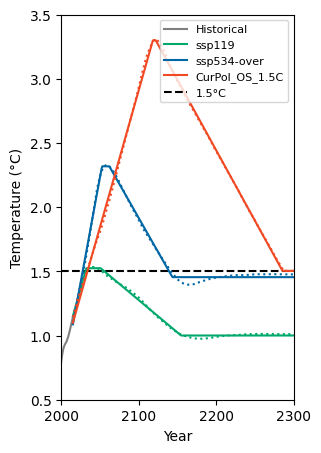

In [113]:
fig,ax=plt.subplots(figsize=(3,5))
ax.plot(xdata[:t_ref-1850+1]+1850,np.median(temps,axis=1)[:t_ref-1850+1],color='gray',label='Historical')
for i in range(3):
    ax.plot(xdata+t_ref,temps_to_plot[i][t_ref-1850:], color=colors[i],ls=':')
    ax.plot(xdata+t_ref,OS_model(xdata,
                                 *popts_to_plot[i]),
                                 # *([np.median(temps,axis=1)[t_ref-1850]] + list(popts_of_m)[1:])),
            color=colors[i],label=scens_to_plot[i])#*np.median(popts,axis=0)))
ax.set_xlim([2000,2300])
ax.set_ylim(0.5,3.5)
ax.set_xlabel('Year')
ax.set_ylabel('Temperature (°C)')
ax.plot([2000,2300],[1.5]*2,c='k',ls='--',zorder=0,label='1.5°C')
ax.legend(fontsize=8)
fig.savefig('../../Figures/Overshoots/Conference/PIK_ToC_a.png',bbox_inches='tight')

In [70]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

In [74]:
# Burn-in 1850-2015
years_burn_in = np.arange(1850,2016) # up to and including 2015
no_burn_years = len(years_burn_in)
pc_burn = np.ones((no_burn_years,len(df_TEs)))
pc_burn *= q_c
pr_burn = np.ones((no_burn_years,len(df_TEs)))
pr_burn *= q_r
for t in years_burn_in-1850:
    pc_burn[t,:] *= temp_response(temps_to_plot[0][t], T_lim, betas)
    pr_burn[t,:] *= (1-temp_response(temps_to_plot[0][t], T_lim, betas))

D_burn = np.zeros((len_sample,len(df_TEs)))
for r in tqdm.tqdm(range(len_sample)):
    for t in range(1,no_burn_years):
        D_burn[r,:] = environmental_update(D_burn[r,:],
                                           A[r],
                                           pc=pc_burn[t,:],
                                           pr=pr_burn[t,:])

100%|███████████████████████████████████████| 500/500 [00:00<00:00, 1083.45it/s]


In [80]:
years = np.arange(2015,2301)
no_years=len(years)
D = [np.zeros((len_sample,len(df_TEs),no_years)) for i in range(3)]

pcs = [np.ones((no_years,len(df_TEs)))*q_c.reshape((1,len(df_TEs))) for s in scenarios]
prs = [np.ones((no_years,len(df_TEs)))*q_r.reshape((1,len(df_TEs))) for s in scenarios]

temps_stylised = [OS_model(xdata,*popts_to_plot[i]) for i in range(3)]

for i in range(3):
    for r in range(len_sample):
        D[i][r,:,0] = D_burn[r,:]
    for t in tqdm.tqdm(range(1,no_years)):
        pcs[i][t,:] *= temp_response(temps_stylised[i][t], T_lim, betas)
        prs[i][t,:] *= 1-temp_response(temps_stylised[i][t], T_lim, betas)
        for r in range(len_sample):
            D[i][r,:,t] = environmental_update(D[i][r,:,t-1],A[r],
                                               pc=pcs[i][t,:],pr=prs[i][t,:])


# for i in tqdm.tqdm(range(3)):
#     for t in range(1,no_years):
#         for r in range(len_sample):
#             D[i][r,:,t] = environmental_update(D[i][r,:,t-1],A[r],
#                                                  pc=pcs[i][t,:],pr=prs[i][t,:])

100%|████████████████████████████████████████| 285/285 [00:00<00:00, 353.34it/s]


In [84]:
D[0].shape

(500, 9, 286)

In [85]:
D_nr = [np.delete(d,6,axis=1) for d in D]
TR = [k_risk(d,1,axis=1) for d in D_nr] # tipping risk

In [93]:
D_nr[0].shape

(500, 8, 286)

In [86]:
TR[0].shape

(500, 286)

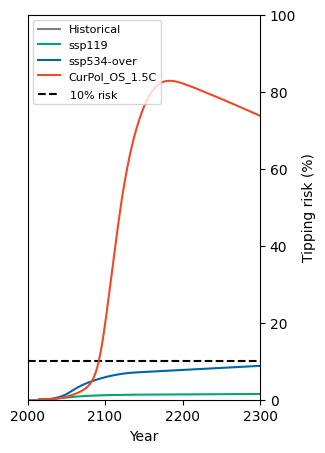

In [115]:
fig,ax=plt.subplots(figsize=(3,5))
ax.plot([2000,2015],[np.median(k_risk(D_nr[0][:,:,0],1,axis=1))]*2,
        color='gray',label='Historical')
for i in range(3):
    # ax.plot(xdata+t_ref,temps_to_plot[i][t_ref-1850:], color=colors[i],ls=':')
    ax.plot(xdata+t_ref,np.median(TR[i], axis=0)*100,
                                 # *([np.median(temps,axis=1)[t_ref-1850]] + list(popts_of_m)[1:])),
            color=colors[i],label=scens_to_plot[i])#*np.median(popts,axis=0)))
ax.set_xlim([2000,2300])
ax.set_ylim(0,100)
ax.yaxis.tick_right()
ax.set_xlabel('Year')
ax.set_ylabel('Tipping risk (%)')
ax.yaxis.set_label_position("right")
ax.plot([2000,2300],[10]*2,c='k',ls='--',zorder=0,label=r'$10\%$ risk')
ax.legend(fontsize=8,loc='upper left')
fig.savefig('../../Figures/Overshoots/Conference/PIK_ToC_b.png',bbox_inches='tight')

In [82]:
help(k_risk)

Help on function k_risk in module util.overshoots:

k_risk(D, k, axis=1)
    Given a vector, $D=(D_i)$, of $N$ individual probabilities,
     k_risk calculates, along the given axis,
     a cumulative probability that :
        - $k$ or more elements are in the degraded state
        - $N-k-1$ or fewer elements are in the prosperous state
     (above statements are equivalent to one another)

    It does this by treating each element as random variable, say $X_i$,
     which is 0 for the prosperous state and 1 for the degraded state,
     and which is distributed as a Bernoulli random variable. In other words, each element is
     Bernoulli distributed with shape parameter $D_i$, $X_i \sim        ext{Bern}(D_i)$.

    In notation this fn outputs $\mathbb{P}(\sum_i X_i \geq k)$,
     which is possible analytically since the sum of independent Bernoulli RVs
     is Poisson binomial distributed i.e. $Z=\sum_i X_i \sim    ext{PB}(D)$
     [see https://en.wikipedia.org/wiki/Poisson_binomial